In [ ]:
 import pandas as pd
 import matplotlib.pyplot as plt

 from sklearn.preprocessing import StandardScaler
 from scipy. spatial.distance import pdist,squareform
 from scipy.cluster.hierarchy import linkage,dendrogram,fcluster

In [ ]:
df = pd.read_csv("/content/fitness_health_tracking.csv")
print("First 5 records:")
print(df.head())

First 5 records:
  User_ID  Daily_Steps  Calories_Burned  Workout_Duration  Hours_Sleep  \
0   U0001        10426           966.47               101          7.2   
1   U0002        13459           855.07                43          7.5   
2   U0003         5298           303.72                14          8.4   
3   U0004         5841           842.68                52          5.2   
4   U0005         7343           708.11                35          8.6   

  Activity_Type Diet_Preference  Gender Age_Group  
0       Cycling      Vegetarian   Other       51+  
1           Gym            Keto    Male       51+  
2          Yoga           Vegan  Female     18-25  
3       Running  Non-Vegetarian  Female     18-25  
4       Walking            Keto   Other     36-50  


In [ ]:
print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nMissing Values:")
print(df.isnull().sum())




Dataset Shape:
(350, 9)

Column Names:
Index(['User_ID', 'Daily_Steps', 'Calories_Burned', 'Workout_Duration',
       'Hours_Sleep', 'Activity_Type', 'Diet_Preference', 'Gender',
       'Age_Group'],
      dtype='object')

Missing Values:
User_ID             0
Daily_Steps         0
Calories_Burned     0
Workout_Duration    0
Hours_Sleep         0
Activity_Type       0
Diet_Preference     0
Gender              0
Age_Group           0
dtype: int64


In [ ]:
features=[
    'Daily_Steps',
    'Calories_Burned',
    'Workout_Duration',
    'Hours_Sleep'
]

X = df[features]

print("\nSelected Features:")
print(X.head())



Selected Features:
   Daily_Steps  Calories_Burned  Workout_Duration  Hours_Sleep
0        10426           966.47               101          7.2
1        13459           855.07                43          7.5
2         5298           303.72                14          8.4
3         5841           842.68                52          5.2
4         7343           708.11                35          8.6


In [ ]:
scaler=StandardScaler()

X_scaled=scaler.fit_transform(X)
print("\nScaled Data:")
print(X_scaled[:5])


Scaled Data:
[[-0.09849897  0.02195891  1.13645592  0.43916988]
 [ 0.47815707 -0.26989643 -0.52997395  0.65137806]
 [-1.07347165 -1.71437081 -1.36318889  1.28800259]
 [-0.97023254 -0.30235683 -0.27139001 -0.97555131]
 [-0.68466137 -0.65491494 -0.75982635  1.42947471]]


In [ ]:
X_scaled_df=pd.DataFrame(
    X_scaled,
    columns=features
)

print("\nScaled Data:")
print(X_scaled_df.head())



Scaled Data:
   Daily_Steps  Calories_Burned  Workout_Duration  Hours_Sleep
0    -0.098499         0.021959          1.136456     0.439170
1     0.478157        -0.269896         -0.529974     0.651378
2    -1.073472        -1.714371         -1.363189     1.288003
3    -0.970233        -0.302357         -0.271390    -0.975551
4    -0.684661        -0.654915         -0.759826     1.429475


In [ ]:
distance=pdist(
    X_scaled_df,
    metric='euclidean'
)
distance_matrix=squareform(distance)

print("\nDistance Matrix:")
print(distance_matrix[:5,:5])


Distance Matrix:
[[0.         1.79992571 3.3066832  2.20194603 2.31912369]
 [1.79992571 0.         2.3650784  2.1937755  1.46923534]
 [3.3066832  2.3650784  0.         2.88446579 1.28750957]
 [2.20194603 2.1937755  2.88446579 0.         2.49570999]
 [2.31912369 1.46923534 1.28750957 2.49570999 0.        ]]


In [ ]:
Z = linkage(
    X_scaled_df,
    method='single'
)

print("\nLinkage Matrix:")
print(Z[:10])


Linkage Matrix:
[[1.10000000e+01 1.51000000e+02 1.04936300e-01 2.00000000e+00]
 [2.85000000e+02 2.95000000e+02 1.18098996e-01 2.00000000e+00]
 [6.80000000e+01 2.29000000e+02 1.24583493e-01 2.00000000e+00]
 [1.55000000e+02 1.98000000e+02 1.33044236e-01 2.00000000e+00]
 [8.20000000e+01 1.50000000e+02 1.39939826e-01 2.00000000e+00]
 [8.90000000e+01 2.20000000e+02 1.48528876e-01 2.00000000e+00]
 [2.88000000e+02 3.09000000e+02 1.50966480e-01 2.00000000e+00]
 [3.00000000e+01 2.46000000e+02 1.54560100e-01 2.00000000e+00]
 [6.60000000e+01 1.38000000e+02 1.59095928e-01 2.00000000e+00]
 [1.60000000e+01 3.20000000e+01 1.61439004e-01 2.00000000e+00]]


In [ ]:
linkage_df= pd.DataFrame(
    Z,
    columns=[
        'CLuster 1',
        'Cluster2',
        'Distance',
        'Number of Points'

    ]
)

print("\nLinkage Matrix DataFrame:")
print(linkage_df.head(10))



Linkage Matrix DataFrame:
   CLuster 1  Cluster2  Distance  Number of Points
0       11.0     151.0  0.104936               2.0
1      285.0     295.0  0.118099               2.0
2       68.0     229.0  0.124583               2.0
3      155.0     198.0  0.133044               2.0
4       82.0     150.0  0.139940               2.0
5       89.0     220.0  0.148529               2.0
6      288.0     309.0  0.150966               2.0
7       30.0     246.0  0.154560               2.0
8       66.0     138.0  0.159096               2.0
9       16.0      32.0  0.161439               2.0


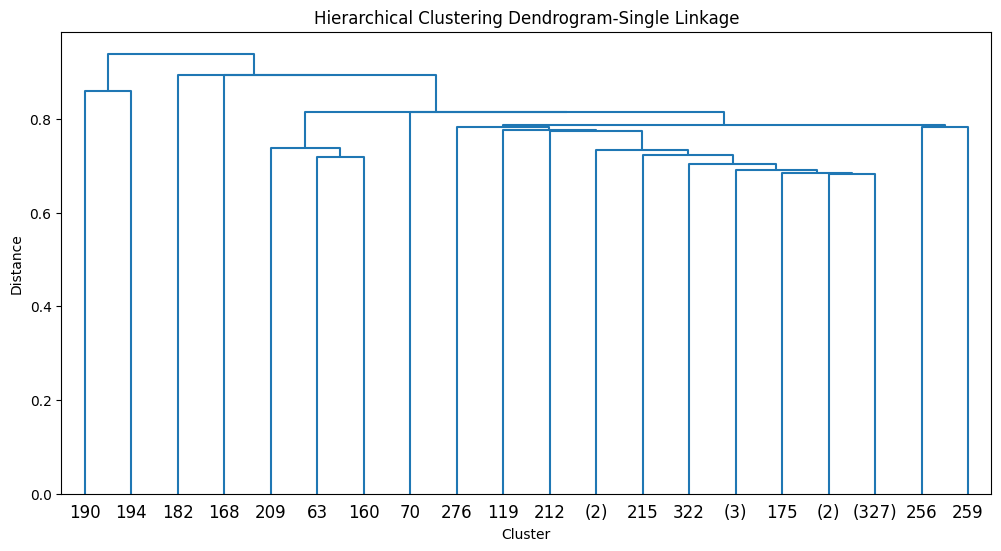

In [ ]:
plt.figure(figsize=(12,6))

dendrogram(
    Z,
    truncate_mode='lastp',
    p=20
)
plt.title("Hierarchical Clustering Dendrogram-Single Linkage")
plt.xlabel("Cluster")
plt.ylabel("Distance")
plt.show()

In [ ]:
df['Cluster']=fcluster(
    Z,
    t=4,
    criterion='maxclust'
)
print("\nFitness Data with Cluster:")

print(
    df[
        [
            'User_ID',
         'Daily_Steps',
         'Calories_Burned',
    'Workout_Duration',
    'Hours_Sleep'
         'Activity_Type',
         'Diet_Preference',
         'Gender',
         'Age_Group',
         'Cluster'
         ]
    ].head(20)
)


Fitness Data with Cluster:


KeyError: "['Hours_SleepActivity_Type'] not in index"